<a href="https://colab.research.google.com/github/Ali010304/metodos-numericos-1/blob/main/Diferencias_Divididas_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Diferencias Divididas


El **método de diferencias divididas** es una técnica de interpolación polinómica que construye un polinomio $P_n(x)$ de grado $n$ a partir de un conjunto de $n + 1$ puntos $(x_0, y_0), (x_1, y_1), \dots, (x_n, y_n)$ usando los coeficientes de una **tabla de diferencias divididas**.

La gran ventaja frente a otras formas de escribir el polinomio es que es **incremental**, es decir, si se agrega un nuevo nodo $(x_{n+1}, y_{n+1})$, no es necesario rehacer todo el polinomio, sino simplemente sumar un término adicional usando la nueva diferencia dividida.

El polinomio de Newton de grado 4 se escribe como:

$$P_n(x) = f[x_0] + f[x_0, x_1](x - x_0) + f[x_0, x_1, x_2](x - x_0)(x - x_1) + ...+f[x_0, ..., x_n](x - x_0)(x - x_1)...(x - x_n) $$

Donde cada coeficiente $f[x_0, x_1, \dots, x_n]$ corresponde a los elementos de la **diagonal principal** de la tabla de diferencias divididas.









In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
sp.init_printing()
x = sp.Symbol("x")


Bibliotecas necesarias para cálculos matemáticos y gráficas, usamos Sympy nuevamente para poder utilizar a $x$ como una variable.

In [ ]:
x_datos = [1.0, 1.3, 1.6, 1.9, 2.2]
y_datos = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]

n = len(x_datos) - 1
F = np.zeros((n + 1, n + 1))

Datos dados por el problema (nodos y sus respectivas evaluaciones).

Por otra parte, se calcula el grado máximo del polinomio y se crea la matriz necesaria para poder almacenar los datos de las operaciones.

In [ ]:
for i in range(n + 1):
  F[i, 0] = y_datos[i]


for j in range(1, n + 1):
  for i in range(j, n + 1):
    F[i, j] = (F[i, j - 1] - F[i - 1, j - 1]) / (x_datos[i] - x_datos[i - j])


cabecera = f"{'x':<6} | {'f[x]':<11}" + "".join(
    [f" | {'Diferencia ' + str(j):<11}" for j in range(1, n + 1)]
)
print(cabecera)
print('-' * len(cabecera))

for i in range(n + 1):
  fila = f'{x_datos[i]:<6.1f} | {F[i, 0]:<11.7f}'
  for j in range(1, n + 1):
    if j <= i:
      fila += f' | {F[i, j]:<11.7f}'
    else:
      fila += f' | {"":<11}'
  print(fila)


diagonal = [float(F[i, i]) for i in range(n + 1)]
print('\n------------------------------------------------------------------')
print('Diagonal de coeficientes')
print(diagonal)

x      | f[x]        | Diferencia 1 | Diferencia 2 | Diferencia 3 | Diferencia 4
--------------------------------------------------------------------------------
1.0    | 0.7651977   |             |             |             |            
1.3    | 0.6200860   | -0.4837057  |             |             |            
1.6    | 0.4554022   | -0.5489460  | -0.1087339  |             |            
1.9    | 0.2818186   | -0.5786120  | -0.0494433  | 0.0658784   |            
2.2    | 0.1103623   | -0.5715210  | 0.0118183   | 0.0680685   | 0.0018251  

------------------------------------------------------------------
Diagonal de coeficientes
[0.7651977, -0.4837056666666664, -0.10873388888888935, 0.06587839506172834, 0.0018251028806604353]


Se inica un ciclo donde se recorreran filas y columnas  para poder almacenar los datos en sus respectivos espacios y crear mostrar los datos necesarios para poder seguir con el problema.

También se crea una tabla que mostrara los resultados obtenidos de las operaciones, además, también se nos mostrará la diagonal de los datos a utilizar.

In [ ]:
x = sp.Symbol("x")
x_eval = 1.5

a = [float(F[i, i]) for i in range(n + 1)]
print("Coeficientes de la diagonal:")
print(a)

P = (
    a[0]
    + a[1] * (x - x_datos[0])
    + a[2] * (x - x_datos[0]) * (x - x_datos[1])
    + a[3] * (x - x_datos[0]) * (x - x_datos[1]) * (x - x_datos[2])
    + a[4]
    * (x - x_datos[0])
    * (x - x_datos[1])
    * (x - x_datos[2])
    * (x - x_datos[3])
)

P_simp = sp.simplify(P)

print("\nPolinomio final simplificado:")
display(P_simp)

print("\nEvaluado en x = 1.5:", float(P_simp.subs(x, x_eval)))

Coeficientes de la diagonal:
[0.7651977, -0.4837056666666664, -0.10873388888888935, 0.06587839506172834, 0.0018251028806604353]

Polinomio final simplificado:


                     4                       3                      2          ↪
0.00182510288066044⋅x  + 0.0552927983538978⋅x  - 0.343046604938247⋅x  + 0.0733 ↪

↪                                   
↪ 913477366034⋅x + 0.977735055967085


Evaluado en x = 1.5: 0.5118199942386832


La diferencia clara respecto a Neville, se toman los elementos de la diagonal principal y se escriben de acuerdo a a forma establecida para este método.
Una vez escrito se utiliza **sympy.simplify** para poder desarrollar los parentesis, agrupar términos y simplificar el polinomio para poder mostrarlo de una forma limpia y ordenada.

Por último, se nos muestra el resultado de la evalucion de dicho polinomio evaluado en $1.5$

Polinomio actual: 0.00182510288066044*x**4 + 0.0552927983538978*x**3 - 0.343046604938247*x**2 + 0.0733913477366034*x + 0.977735055967085


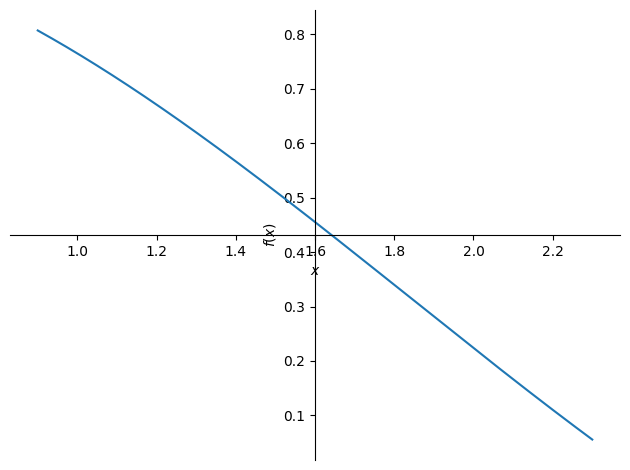

In [ ]:

print("Polinomio actual:", P_simp)
sp.plot(P_simp, (x, min(x_datos) - 0.1, max(x_datos) + 0.1))

Comparación con Geogébra. 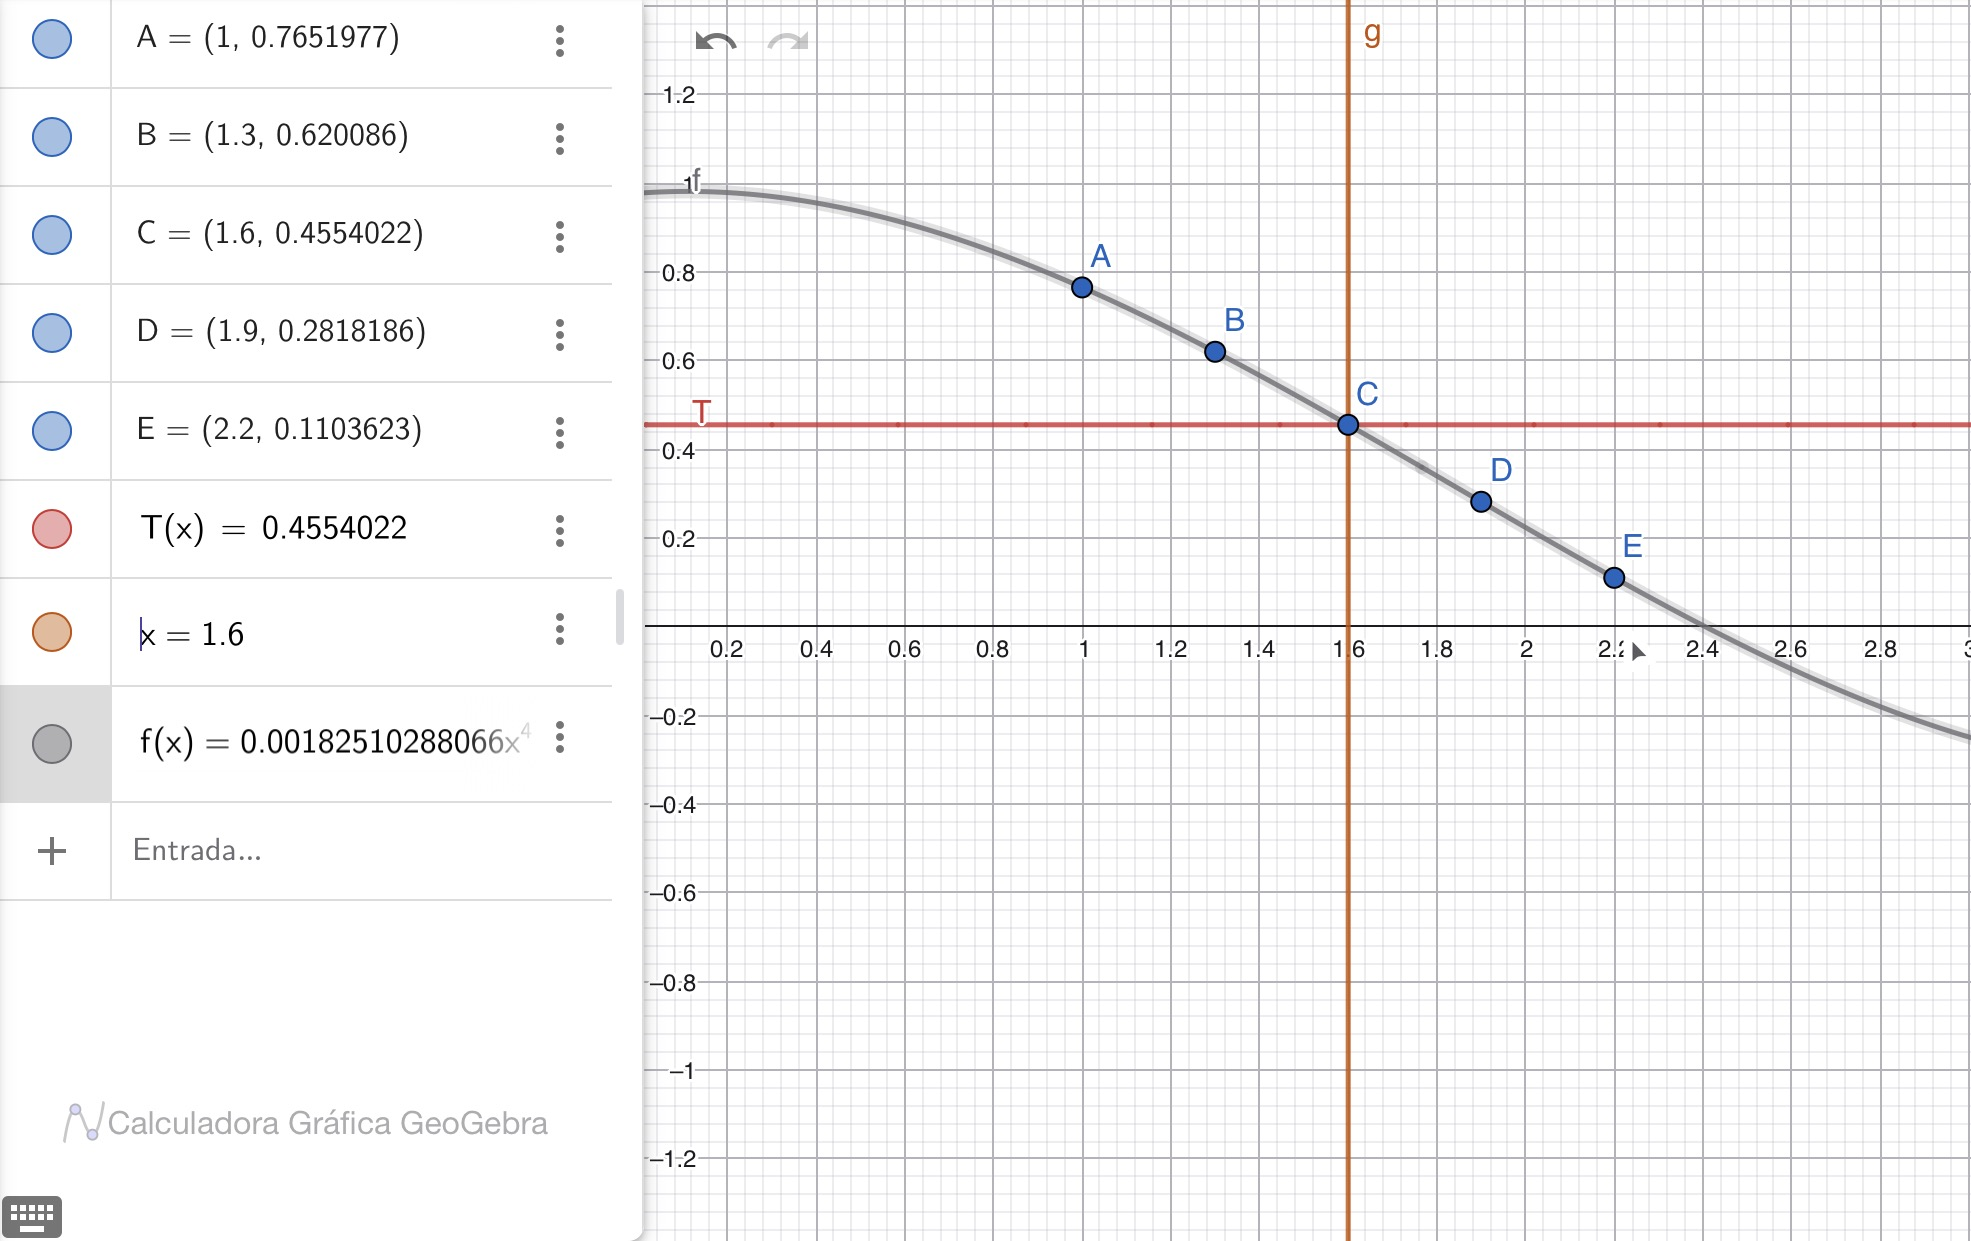